In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp

import numpy as np
from numpy.typing import ArrayLike

from scipy.special import iv, kv, ive, kve

from prodpy.decline import Arps
from prodpy.transient import InfiniteActing

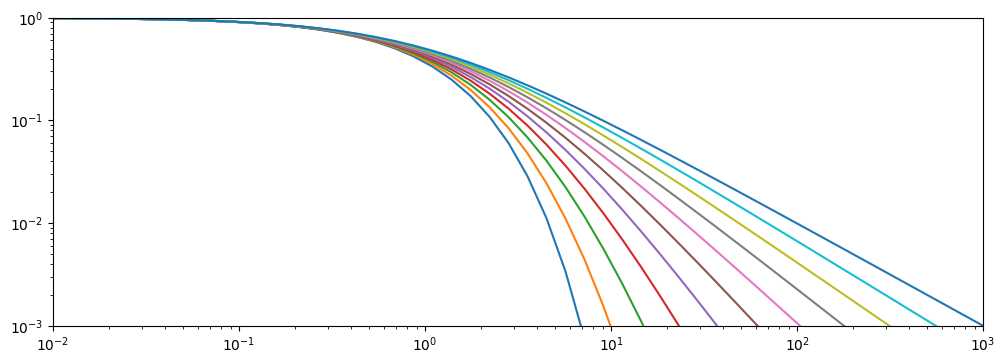

In [2]:
t = np.logspace(-2,3)

plt.figure(figsize=(12,4))

for b in np.arange(0,1.01,0.1):
    if b == 0:
        plt.loglog(t,Arps.exp.qDd(t))
    elif b == 1:
        plt.loglog(t,Arps.har.qDd(t))
    else:
        plt.loglog(t,Arps.hyp.qDd(b, t))

plt.ylim(bottom=0.001,top=1)
plt.xlim((1e-2,1e3))

plt.show()

In [3]:
# def stehfest_coefficients(n_terms: int = 12) -> np.ndarray:
#     """
#     Compute Gaver-Stehfest coefficients for numerical inverse Laplace transform.

#     Parameters
#     ----------
#     n_terms : int
#         Number of Stehfest terms. Must be even.
#         10 or 12 is usually stable for engineering type-curve work.

#     Returns
#     -------
#     np.ndarray
#         Stehfest coefficients indexed from 1 to n_terms.
#     """
#     if n_terms % 2 != 0:
#         raise ValueError("n_terms must be even.")

#     v = np.zeros(n_terms + 1)

#     for k in range(1, n_terms + 1):
#         summation = 0.0

#         j_min = (k + 1) // 2
#         j_max = min(k, n_terms // 2)

#         for j in range(j_min, j_max + 1):
#             numerator = (j ** (n_terms // 2)) * math.factorial(2 * j)

#             denominator = (
#                 math.factorial(n_terms // 2 - j)
#                 * math.factorial(j)
#                 * math.factorial(j - 1)
#                 * math.factorial(k - j)
#                 * math.factorial(2 * j - k)
#             )

#             summation += numerator / denominator

#         v[k] = ((-1) ** (k + n_terms // 2)) * summation

#     return v


def k1_over_i1(z: np.ndarray) -> np.ndarray:
    """
    Stable evaluation of K1(z) / I1(z).

    For large z, direct scipy.special.kv / iv may underflow or overflow.
    Scaled Bessel functions are used for stability.
    """
    z = np.asarray(z, dtype=float)
    ratio = np.empty_like(z)

    small = z < 50.0
    large = ~small

    ratio[small] = kv(1, z[small]) / iv(1, z[small])

    # K1/I1 = [kve(1,z) exp(-z)] / [ive(1,z) exp(z)]
    #       = [kve(1,z) / ive(1,z)] exp(-2z)
    ratio[large] = (kve(1, z[large]) / ive(1, z[large])) * np.exp(-2.0 * z[large])

    return ratio


def qbar_constant_pressure_radial(s: np.ndarray, reD: float) -> np.ndarray:
    """
    Laplace-space dimensionless rate for radial flow with:
        inner boundary: constant pressure at rD = 1
        outer boundary: no-flow at rD = reD

    The solution is written in terms of modified Bessel functions.

    Parameters
    ----------
    s : array-like
        Laplace variable.
    reD : float
        Dimensionless external radius, re / rw.

    Returns
    -------
    np.ndarray
        Laplace transform of qD(tD).
    """
    s = np.asarray(s, dtype=float)
    u = np.sqrt(s)

    eta = k1_over_i1(u * reD)

    numerator = kv(1, u) - eta * iv(1, u)
    denominator = kv(0, u) + eta * iv(0, u)

    return (u / s) * (numerator / denominator)

def inverse_laplace_stehfest_NEW(func, t: ArrayLike, degree: int = 12, **kwargs):
    """
    Inverse Laplace transform using mpmath's Stehfest method.
    """

    t = np.asarray(t, dtype=float)

    if np.any(t <= 0):
        raise ValueError("t must be strictly positive.")

    values = [
        mp.invertlaplace(
            lambda s: func(s, **kwargs),
            float(ti),
            method="stehfest",
            degree=degree,
        )
        for ti in t.ravel()
    ]

    result = np.array(values, dtype=float).reshape(t.shape)

    return result.item() if result.ndim == 0 else result


# def inverse_laplace_stehfest(func, t: np.ndarray, n_terms: int = 12, **kwargs) -> np.ndarray:
#     """
#     Numerical inverse Laplace transform using the Gaver-Stehfest algorithm.
#     """
#     t = np.asarray(t, dtype=float)
#     ln2 = np.log(2.0)
#     v = stehfest_coefficients(n_terms)

#     result = np.zeros_like(t)

#     for k in range(1, n_terms + 1):
#         s = k * ln2 / t
#         result += v[k] * func(s, **kwargs)

#     return (ln2 / t) * result


def qD_constant_pressure(tD: np.ndarray, reD: float, n_terms: int = 12) -> np.ndarray:
    """
    Compute qD(tD) for finite radial reservoir under constant well pressure.
    """
    return inverse_laplace_stehfest_NEW(
        qbar_constant_pressure_radial,
        tD,
        degree=n_terms,
        reD=reD,
    )


def fetkovich_transform(tDd: np.ndarray, reD: float) -> tuple[np.ndarray, np.ndarray]:
    """
    Convert constant-pressure radial qD(tD) solution into Fetkovich decline variables.

    qDd = qD * [ln(reD) - 1/2]

    tDd = tD / {0.5 * [(reD)^2 - 1] * [ln(reD) - 1/2]}

    Therefore:

    tD = tDd * {0.5 * [(reD)^2 - 1] * [ln(reD) - 1/2]}
    """
    b = np.log(reD) - 0.5

    tD_scale = 0.5 * (reD**2 - 1.0) * b
    tD = tDd * tD_scale

    qD = qD_constant_pressure(tD, reD=reD, n_terms=12)
    qDd = qD * b

    return tDd, qDd

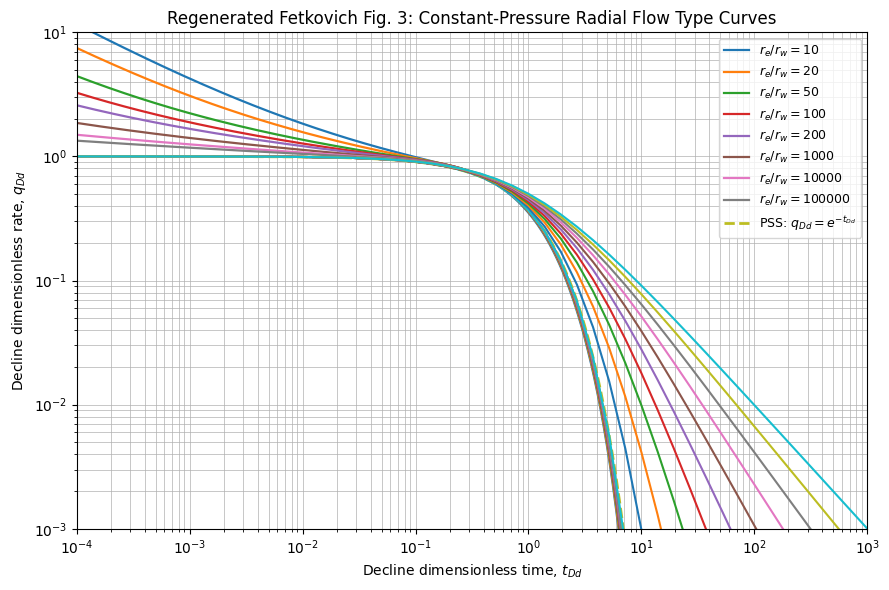

In [6]:
# Decline-curve dimensionless time range.
tDd = np.logspace(-4, 1, 180)

# Approximate radius ratios shown in Fetkovich Fig. 3.
reD_values = [10, 20, 50, 100, 200, 1_000, 10_000, 100_000]

plt.figure(figsize=(9, 6))

for reD in reD_values:
    x, y = fetkovich_transform(tDd, reD)

    plt.loglog(x, y, linewidth=1.6, label=fr"$r_e/r_w={reD:g}$")

# Long-time pseudo-steady-state exponential decline reference.
# In Fetkovich decline variables, finite-boundary solutions converge to this line.
t_exp = np.logspace(-4, 1, 180)
q_exp = np.exp(-t_exp)

plt.loglog(t_exp, q_exp, linestyle="--", linewidth=2.0, label=r"PSS: $q_{Dd}=e^{-t_{Dd}}$")

t = np.logspace(-4,3)

for b in np.arange(0,1.01,0.1):
    if b == 0:
        plt.loglog(t,Arps.exp.qDd(t))
    elif b == 1:
        plt.loglog(t,Arps.har.qDd(t))
    else:
        plt.loglog(t,Arps.hyp.qDd(b, t))

plt.xlabel(r"Decline dimensionless time, $t_{Dd}$")
plt.ylabel(r"Decline dimensionless rate, $q_{Dd}$")
plt.title("Regenerated Fetkovich Fig. 3: Constant-Pressure Radial Flow Type Curves")

plt.xlim(1e-4, 1e3)
plt.ylim(1e-3, 1e1)

plt.grid(True, which="both", linewidth=0.5)
plt.legend(fontsize=9)
plt.tight_layout()

plt.show()